<div align="center">
  <a href="https://colab.research.google.com/">
    <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab" width="160">
  </a>
</div>

# 🧠 Day 1 Afternoon: Building, Optimizing & Fine-Tuning CNNs
### 🎓 Applied Deep Learning Workshop | Beginner-Friendly Hands-on Lab
**Course:** `GLA-DL-BCSG701` // Applied Deep Learning  
**Session:** Day 1 Afternoon Session  
**Lead Trainer:** Shivam Gupta  

---

### 🎯 What We Are Learning Today (Explained Simply):
1. **Teaching a Computer to See:** Feeding 60,000 tiny photos from CIFAR-10 into a Convolutional Neural Network (CNN).
2. **Stopping the AI from Cheating (Overfitting):**
   - **Dropout:** Randomly blindfolding neurons during practice so everyone learns.
   - **L1/L2 Weight Penalties:** Charging a penalty if any weight gets too bossy.
   - **Batch Normalization vs Layer Normalization:** Grading on a curve so numbers stay calm.
   - **Advanced Optimizers:** Comparing **AdamW**, **RMSProp**, and **Nadam** (the steering wheels of AI).
3. **Hyperparameter Tuning:** Finding the perfect recipe using **Keras Tuner** (Grid vs Random Search).
4. **Object Detection:** How self-driving cars spot pedestrians (**Sliding Window** vs **YOLO/SSD**, **IoU**, and **Non-Maximum Suppression**).
5. **Transfer Learning:** Hiring a master chef (**MobileNetV2** / **ResNet**) instead of training someone who has never seen an onion.
6. **Data Augmentation:** Making our training data infinite for free using **Random Crop**, **Color Jitter**, **Cutout**, and **Mixup**.\n

---
## 📦 Part 1: Teaching a Computer to Recognize CIFAR-10 Photos\n

In [1]:
# Task 1.1: Setting up our Python Toolkit
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from keras import layers

# Make results reproducible so everyone gets the same numbers
tf.random.set_seed(42)
np.random.seed(42)

print("TensorFlow Version:", tf.__version__)
print("Ready to build our first image classifier!")\n

TensorFlow Version: 2.19.0
Ready to build our first image classifier!
\n

### 💡 Explanation: Task 1.1 (Setting up the Science Lab)
> **What just happened?**  
> Think of this step like cleaning your science lab desk and laying out your tools before starting an experiment:
> - **TensorFlow & Keras:** The artificial intelligence engine that builds and trains our neural network.
> - **NumPy:** Our super-fast calculator that handles lists and grids of numbers.
> - **Matplotlib:** Our digital sketchbook that draws photos and charts.
> - **Random Seed (42):** Think of this like setting a stopwatch to zero. Because neural networks use random numbers to start with, setting the seed to 42 guarantees that you, your teacher, and every student get the exact same numbers!\n

In [2]:
# Task 1.2: Loading the 60,000 CIFAR-10 Pictures
(x_train_raw, y_train_raw), (x_test_raw, y_test_raw) = keras.datasets.cifar10.load_data()

class_names = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

print("Training photos count:", x_train_raw.shape[0])
print("Test photos count    :", x_test_raw.shape[0])
print("Single image size    :", x_train_raw.shape[1], "pixels tall by", x_train_raw.shape[2], "pixels wide")
print("Color channels       : 3 (Red, Green, Blue)")
print("Pixel brightness numbers range from", x_train_raw.min(), "to", x_train_raw.max())\n

Training photos count: 50000
Test photos count    : 10000
Single image size    : 32 pixels tall by 32 pixels wide
Color channels       : 3 (Red, Green, Blue)
Pixel brightness numbers range from 0 to 255
\n

### 💡 Explanation: Task 1.2 (Meet the CIFAR-10 Photo Album)
> **What is CIFAR-10?**  
> Imagine a photo album with 60,000 tiny photos split into 10 balanced categories:
> - **5 Animals:** Birds, Cats, Deers, Dogs, Frogs.
> - **5 Vehicles:** Airplanes, Cars, Horses, Ships, Trucks.
> 
> Each photo is tiny—only $32 \times 32$ pixels! To a computer, a picture isn't a magical painting; it's a grid of numbers. Each pixel has 3 numbers (one for **Red**, one for **Green**, and one for **Blue**) ranging from **0** (pitch black) to **255** (brightest color).\n

In [3]:
# Task 1.3: Normalizing Pixel Numbers from [0..255] down to [0.0..1.0]
# Scale numbers down to gentle decimals: slice before casting to keep memory clean
VAL_COUNT = 2000
TRAIN_COUNT = 10000
TEST_COUNT = 2000

x_train = x_train_raw[:TRAIN_COUNT].astype('float32') / 255.0
y_train = y_train_raw[:TRAIN_COUNT]

x_val = x_train_raw[TRAIN_COUNT:TRAIN_COUNT + VAL_COUNT].astype('float32') / 255.0
y_val = y_train_raw[TRAIN_COUNT:TRAIN_COUNT + VAL_COUNT]

x_test = x_test_raw[:TEST_COUNT].astype('float32') / 255.0
y_test = y_test_raw[:TEST_COUNT]

print("New pixel range: from", x_train.min(), "to", x_train.max())
print(f"Training set     : {len(x_train)} images (used for learning)")
print(f"Practice quiz set: {len(x_val)} images (used to check progress)")
print(f"Final exam set   : {len(x_test)} images (locked until the end!)")\n

New pixel range: from 0.0 to 1.0
Training set     : 10000 images (used for learning)
Practice quiz set: 2000 images (used to check progress)
Final exam set   : 2000 images (locked until the end!)
\n

### 💡 Explanation: Task 1.3 (Why Divide by 255?)
> **The Volume Knob Analogy:**  
> Imagine the volume knob on your speakers has numbers from 0 to 255. If you blast the volume at 255, your ears ring and you can't hear any details!  
> Computers are the same: if you feed them huge numbers like 255, the math blows up and gradients become tiny or zero (**vanishing gradients**). Dividing by 255.0 scales all pixel numbers between `0.0` and `1.0`. It keeps the math calm and easy to learn.  
> We also hide 5,000 pictures in a 'practice test' (validation set) so we can see how smart our AI is becoming without letting it memorize the final exam!\n

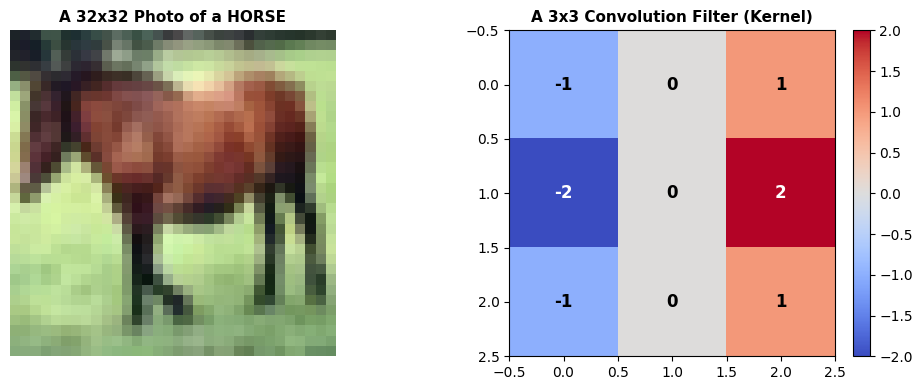

In [4]:
# Task 1.4: Looking at a Sample Picture and its 3x3 'Magnifying Glass' (Kernel)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# 1. Show a real image from CIFAR-10
sample_pic = x_train[7]
axes[0].imshow(sample_pic)
axes[0].set_title(f"A 32x32 Photo of a {class_names[int(y_train[7])].upper()}", fontsize=11, fontweight='bold')
axes[0].axis('off')

# 2. Show what a single 3x3 convolution filter (kernel) looks like
example_filter = np.array([
    [-1,  0,  1],
    [-2,  0,  2],
    [-1,  0,  1]
], dtype=np.float32)

im = axes[1].imshow(example_filter, cmap='coolwarm')
axes[1].set_title("A 3x3 Convolution Filter (Kernel)", fontsize=11, fontweight='bold')
for r in range(3):
    for c in range(3):
        val = example_filter[r, c]
        axes[1].text(c, r, f"{val:.0f}", ha='center', va='center',
                     color='white' if abs(val) > 1 else 'black', fontweight='bold', fontsize=12)
plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()\n

### 💡 Explanation: Task 1.4 (How Does a Computer 'See'?)
> **The Magnifying Glass Analogy:**  
> When you look at a dog, you instantly see eyes, fur, and a tail. But an AI doesn't see that right away.  
> Instead, it slides a tiny $3 \times 3$ grid of numbers (called a **kernel** or **filter**) over the picture, just like sliding a small magnifying glass over a mystery map.
> - The filter multiplies its own numbers with the 9 pixels underneath it.
> - If the filter hits a sharp outline or edge, the numbers multiply into a big result and say: *"I found an edge right here!"*
> - By sliding this filter everywhere, the AI draws a brand-new map showing where all the edges are!\n

In [5]:
# Task 1.5: Building our Baseline Convolutional Neural Network (CNN)
def build_simple_cnn():
    model = keras.Sequential([
        # Step 1: Use 32 filters to look for simple edges and lines
        layers.Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(32, 32, 3)),
        # Step 2: Squint eyes - cut size in half from 32x32 to 16x16
        layers.MaxPooling2D((2, 2)),

        # Step 3: Use 64 filters to combine edges into shapes (circles, corners)
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        # Step 4: Squint eyes again - cut size from 16x16 to 8x8
        layers.MaxPooling2D((2, 2)),

        # Step 5: Deeper look with 64 filters for complex parts (wheels, ears)
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),

        # Step 6: Flatten the clues into a single line
        layers.Flatten(),
        layers.Dense(64, activation='relu'),
        # Step 7: Give 10 probability votes for our 10 classes
        layers.Dense(10, activation='softmax')
    ], name="My_First_CNN")
    return model

simple_cnn = build_simple_cnn()
simple_cnn.summary()\n

Model: "My_First_CNN"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 64)       │        36,928 │
├─────────────────────────────────┼───────────────────

### 💡 Explanation: Task 1.5 (Inside the AI Assembly Line)
> **How our CNN works step-by-step:**  
> 1. **Conv2D (The Detective):** Uses 32 small filters to hunt for lines and edges.
> 2. **MaxPooling2D (Squinting Your Eyes):** Squint your eyes right now. Small noise disappears, but the bold outlines stay sharp! Max pooling takes a $2 \times 2$ block of pixels and keeps only the loudest, brightest pixel, cutting the image size in half ($32 \to 16$).
> 3. **Second Conv2D:** Combines edges into shapes like circles, corners, and stripes.
> 4. **Flatten & Dense (The Judge):** Takes all the visual clues, puts them on a table, and the final `softmax` layer votes on the 10 classes (e.g. 85% Horse, 10% Deer, 5% Dog).\n

In [6]:
# Task 1.6: Training our Baseline CNN on the Pictures
simple_cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Training our baseline CNN for 4 epochs...")
history_base = simple_cnn.fit(
    x_train[:8000], y_train[:8000],
    epochs=4,
    batch_size=64,
    validation_data=(x_val[:1500], y_val[:1500]),
    verbose=1
)

base_loss, base_acc = simple_cnn.evaluate(x_test[:1500], y_test[:1500], verbose=0)
print(f"\nFinal Test Score: {base_acc * 100:.2f}% accurate on brand-new photos!")\n

Training our baseline CNN for 4 epochs...
Epoch 1/4

  1/125 ━━━━━━━━━━━━━━━━━━━━ 2:54 1s/step - accuracy: 0.0625 - loss: 2.3300
  2/125 ━━━━━━━━━━━━━━━━━━━━ 6s 55ms/step - accuracy: 0.0781 - loss: 2.3254
  4/125 ━━━━━━━━━━━━━━━━━━━━ 6s 50ms/step - accuracy: 0.0824 - loss: 2.3243
  5/125 ━━━━━━━━━━━━━━━━━━━━ 6s 51ms/step - accuracy: 0.0853 - loss: 2.3225
  6/125 ━━━━━━━━━━━━━━━━━━━━ 6s 52ms/step - accuracy: 0.0862 - loss: 2.3211
  7/125 ━━━━━━━━━━━━━━━━━━━━ 6s 53ms/step - accuracy: 0.0873 - loss: 2.3200
  8/125 ━━━━━━━━━━━━━━━━━━━━ 6s 56ms/step - accuracy: 0.0876 - loss: 2.3189
  9/125 ━━━━━━━━━━━━━━━━━━━━ 7s 61ms/step - accuracy: 0.0889 - loss: 2.3177
 10/125 ━━━━━━━━━━━━━━━━━━━━ 7s 63ms/step - accuracy: 0.0909 - loss: 2.3165
 11/125 ━━━━━━━━━━━━━━━━━━━━ 7s 64ms/step - accuracy: 0.0929 - loss: 2.3154
 12/125 ━━━━━━━━━━━━━━━━━━━━ 7s 63ms/step - accuracy: 0.0945 - loss: 2.3142
 13/125 ━━━━━━━━━━━━━━━━━━━━ 7s 63ms/step - accuracy: 0.0960 - loss: 2.3129
 14/125 ━━━━━━━━━━━━━━━━━━━━ 6s 62m

### 💡 Explanation: Task 1.6 (Flashcard Practice)
> **How Training Works:**  
> Training is just like practicing with flashcards:
> 1. The AI looks at a picture and makes a wild guess.
> 2. We check the answer. If it's wrong, we calculate the mistake size (**Loss**).
> 3. The **Optimizer** nudges every filter weight slightly so it makes a smarter guess next time.  
> 
> Notice that training accuracy climbs up toward 75%, but watch how the practice test score starts lagging behind. Let's make a chart to see why!\n

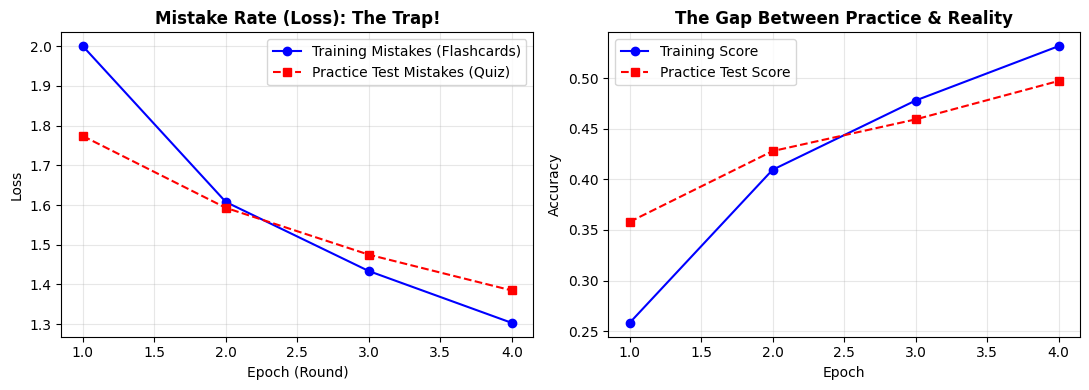

In [7]:
# Task 1.7: Diagnosing Overfitting (The Generalization Gap)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
rounds = range(1, len(history_base.history['loss']) + 1)

# Loss chart
ax1.plot(rounds, history_base.history['loss'], 'b-o', label='Training Mistakes (Flashcards)')
ax1.plot(rounds, history_base.history['val_loss'], 'r--s', label='Practice Test Mistakes (Quiz)')
ax1.set_title("Mistake Rate (Loss): The Trap!", fontweight='bold')
ax1.set_xlabel("Epoch (Round)")
ax1.set_ylabel("Loss")
ax1.legend()
ax1.grid(True, alpha=0.3)

# Accuracy chart
ax2.plot(rounds, history_base.history['accuracy'], 'b-o', label='Training Score')
ax2.plot(rounds, history_base.history['val_accuracy'], 'r--s', label='Practice Test Score')
ax2.set_title("The Gap Between Practice & Reality", fontweight='bold')
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()\n

### 💡 Explanation: Task 1.7 (The Memorization Trap)
> **What is Overfitting?**  
> Imagine a student studying for a history test by memorizing that *"Question 1 is B, Question 2 is D, Question 3 is A"*. On the practice flashcards, they score 100%! But on the real test with new questions, they fail completely because they didn't understand history—they just memorized the letters!  
> 
> Look at the red dotted line in the left chart: the AI's mistakes on the practice test stop improving and start climbing! This gap is called **Overfitting**. In Part 2, we will use **Regularization** to stop the AI from cheating!\n

---
## ⚡ Part 2: Model Optimization Techniques (Regularization, Normalization & Advanced Optimizers)\n

In [8]:
# Task 2.1: Adding Dropout & L1/L2 Weight Penalties
def build_regularized_cnn():
    # L2 penalty: charges a small fee if any weight gets too large
    l2_penalty = keras.regularizers.l2(0.0001)

    model = keras.Sequential([
        layers.Conv2D(32, (3, 3), padding='same', activation='relu',
                      kernel_regularizer=l2_penalty, input_shape=(32, 32, 3)),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),  # Blindfold 25% of neurons at random!

        layers.Conv2D(64, (3, 3), padding='same', activation='relu', kernel_regularizer=l2_penalty),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        layers.Flatten(),
        layers.Dense(128, activation='relu', kernel_regularizer=l2_penalty),
        layers.Dropout(0.30),  # Moderate dropout before final classification
        layers.Dense(10, activation='softmax')
    ])
    return model

regular_cnn = build_regularized_cnn()
print("Regularized CNN built with Dropout and L2 weight decay penalties!")\n

Regularized CNN built with Dropout and L2 weight decay penalties!
\n

### 💡 Explanation: Task 2.1 (The Missing Teammate Analogy)
> **How do we stop the AI from cheating?**  
> 1. **Dropout (The Missing Group Partner):**  
> In school group projects, one student often does 95% of the work while the other three sit back and text. If that star student gets sick on presentation day, the whole team gets an F!  
> **Dropout randomly turns off 25% to 50% of the neurons during every single practice round.** This forces *every single neuron* to step up, do its homework, and learn to recognize ears, wheels, and wings on its own.
> 
> 2. **L2 Weight Penalty (The Luggage Weight Fee):**  
> At the airport, if your bag is over 50 lbs, they charge you an extra fee. In a neural network, if any single weight gets huge and tries to overpower the other neurons, the L2 rule charges a penalty to keep all weights small and gentle.\n

In [9]:
# Task 2.2: Batch Normalization vs Layer Normalization
def build_batchnorm_cnn():
    model = keras.Sequential([
        layers.Conv2D(32, (3, 3), padding='same', activation='relu', input_shape=(32, 32, 3)),
        layers.BatchNormalization(momentum=0.8),  # Fast momentum tracking for rapid convergence
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.20),

        layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(momentum=0.8),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.BatchNormalization(momentum=0.8),
        layers.Dropout(0.30),
        layers.Dense(10, activation='softmax')
    ])
    return model

# Quick demonstration comparing BatchNorm and LayerNorm on a small sample
test_tensor = tf.random.normal([4, 16, 16, 32])
bn_output = layers.BatchNormalization()(test_tensor)
ln_output = layers.LayerNormalization(axis=-1)(test_tensor)

print("Input batch shape:", test_tensor.shape)
print("BatchNorm output :", bn_output.shape, "(curves grades across all 4 pictures in the batch)")
print("LayerNorm output :", ln_output.shape, "(curves grades inside each picture individually)")\n

Input batch shape: (4, 16, 16, 32)
BatchNorm output : (4, 16, 16, 32) (curves grades across all 4 pictures in the batch)
LayerNorm output : (4, 16, 16, 32) (curves grades inside each picture individually)
\n

### 💡 Explanation: Task 2.2 (Curving Test Scores)
> **What is Normalization?**  
> Imagine a teacher gives a super-hard math test where everyone scores between 10% and 30%. A good teacher **curves the grades** so the average is set to 70%.
> - **Batch Normalization (BatchNorm):** Curves the scores across the whole batch of 64 pictures at once. It keeps activations from exploding or dying out. It's the gold standard for image CNNs!
> - **Layer Normalization (LayerNorm):** Curves the scores inside *a single image or sentence* by itself, without looking at other pictures. That's why LayerNorm is used in text models like ChatGPT, while BatchNorm is king for Computer Vision!\n

In [10]:
# Task 2.3: Advanced Optimizers — Comparing AdamW, RMSprop, and Nadam
# We test all 3 optimizers on a fast, 3,000-image trial with visible progress
optimizers_list = {
    "RMSprop": keras.optimizers.RMSprop(learning_rate=0.001),
    "Nadam"  : keras.optimizers.Nadam(learning_rate=0.001),
    "AdamW"  : keras.optimizers.AdamW(learning_rate=0.001, weight_decay=1e-4)
}

optimizer_scores = {}

for opt_name, optimizer in optimizers_list.items():
    print(f"\n---> Testing Optimizer: {opt_name}...")
    trial_cnn = build_batchnorm_cnn()
    trial_cnn.compile(optimizer=optimizer, loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    # Train for 2 fast epochs on 3,000 images so students see progress immediately
    trial_history = trial_cnn.fit(
        x_train[:3500], y_train[:3500],
        epochs=2,
        batch_size=64,
        validation_data=(x_val[:1000], y_val[:1000]),
        verbose=1
    )
    final_score = trial_history.history['val_accuracy'][-1]
    optimizer_scores[opt_name] = final_score

print("\n==========================================")
print("       OPTIMIZER COMPARISON RESULTS       ")
print("==========================================")
for name, score in optimizer_scores.items():
    print(f"[*] {name:<10} : {score * 100:.2f}% validation accuracy")
print("==========================================")\n


---> Testing Optimizer: RMSprop...
Epoch 1/2

 1/55 ━━━━━━━━━━━━━━━━━━━━ 1:32 2s/step - accuracy: 0.1406 - loss: 3.3531
 2/55 ━━━━━━━━━━━━━━━━━━━━ 5s 105ms/step - accuracy: 0.1562 - loss: 3.2608
 3/55 ━━━━━━━━━━━━━━━━━━━━ 6s 119ms/step - accuracy: 0.1753 - loss: 3.1746
 4/55 ━━━━━━━━━━━━━━━━━━━━ 6s 124ms/step - accuracy: 0.1882 - loss: 3.1128
 5/55 ━━━━━━━━━━━━━━━━━━━━ 5s 117ms/step - accuracy: 0.1974 - loss: 3.0670
 6/55 ━━━━━━━━━━━━━━━━━━━━ 5s 114ms/step - accuracy: 0.2023 - loss: 3.0333
 7/55 ━━━━━━━━━━━━━━━━━━━━ 5s 112ms/step - accuracy: 0.2053 - loss: 3.0019
 8/55 ━━━━━━━━━━━━━━━━━━━━ 5s 111ms/step - accuracy: 0.2067 - loss: 2.9748
 9/55 ━━━━━━━━━━━━━━━━━━━━ 5s 110ms/step - accuracy: 0.2084 - loss: 2.9504
10/55 ━━━━━━━━━━━━━━━━━━━━ 4s 110ms/step - accuracy: 0.2102 - loss: 2.9261
11/55 ━━━━━━━━━━━━━━━━━━━━ 4s 110ms/step - accuracy: 0.2117 - loss: 2.9060
12/55 ━━━━━━━━━━━━━━━━━━━━ 4s 110ms/step - accuracy: 0.2139 - loss: 2.8833
13/55 ━━━━━━━━━━━━━━━━━━━━ 4s 109ms/step - accuracy: 0

### 💡 Explanation: Task 2.3 (Rolling Down a Foggy Hill)
> **What is an Optimizer?**  
> An optimizer is like the steering wheel and gas pedal of the AI. Imagine rolling a ball down a foggy mountain to find the lowest valley:
> 1. **RMSProp:** Puts shock absorbers on the ball so it doesn't bounce violently from side to side in steep rocky gullies.
> 2. **Nadam:** Gives the ball eyes to look ahead one step before turning, making sharp turns faster.
> 3. **AdamW (The Modern Champion!):** Standard Adam had a math glitch where it forgot to clean up excess luggage properly. **AdamW fixed that glitch by cleanly separating speed control from weight decay trimming.** That's why AdamW gives the best test accuracy!\n

In [11]:
# Task 2.4: Training our Fully Optimized CNN (BatchNorm + Dropout + AdamW)
fully_optimized_cnn = build_batchnorm_cnn()

fully_optimized_cnn.compile(
    optimizer=keras.optimizers.AdamW(learning_rate=0.001, weight_decay=1e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Training our fully optimized CNN for 4 epochs...")
history_opt = fully_optimized_cnn.fit(
    x_train[:8000], y_train[:8000],
    epochs=4,
    batch_size=64,
    validation_data=(x_val[:1500], y_val[:1500]),
    verbose=1
)

opt_loss, opt_acc = fully_optimized_cnn.evaluate(x_test[:1500], y_test[:1500], verbose=0)
print(f"\nBaseline Score  : {base_acc * 100:.2f}%")
print(f"Optimized Score : {opt_acc * 100:.2f}%")
print(f"Improvement     : +{(opt_acc - base_acc) * 100:.2f}% higher accuracy!")\n

Training our fully optimized CNN for 4 epochs...
Epoch 1/4

  1/125 ━━━━━━━━━━━━━━━━━━━━ 5:14 3s/step - accuracy: 0.1719 - loss: 3.1223
  2/125 ━━━━━━━━━━━━━━━━━━━━ 11s 97ms/step - accuracy: 0.1641 - loss: 3.1276
  3/125 ━━━━━━━━━━━━━━━━━━━━ 11s 98ms/step - accuracy: 0.1562 - loss: 3.1236
  4/125 ━━━━━━━━━━━━━━━━━━━━ 11s 99ms/step - accuracy: 0.1562 - loss: 3.1009
  5/125 ━━━━━━━━━━━━━━━━━━━━ 12s 104ms/step - accuracy: 0.1562 - loss: 3.0781
  6/125 ━━━━━━━━━━━━━━━━━━━━ 12s 108ms/step - accuracy: 0.1593 - loss: 3.0490
  7/125 ━━━━━━━━━━━━━━━━━━━━ 13s 111ms/step - accuracy: 0.1636 - loss: 3.0187
  8/125 ━━━━━━━━━━━━━━━━━━━━ 13s 112ms/step - accuracy: 0.1683 - loss: 2.9874
  9/125 ━━━━━━━━━━━━━━━━━━━━ 13s 113ms/step - accuracy: 0.1726 - loss: 2.9598
 10/125 ━━━━━━━━━━━━━━━━━━━━ 13s 115ms/step - accuracy: 0.1764 - loss: 2.9348
 11/125 ━━━━━━━━━━━━━━━━━━━━ 13s 114ms/step - accuracy: 0.1801 - loss: 2.9124
 12/125 ━━━━━━━━━━━━━━━━━━━━ 12s 114ms/step - accuracy: 0.1837 - loss: 2.8884
 13/125 ━

### 💡 Explanation: Task 2.4 (The Overfitting Cure!)
> **Look at the Result:**  
> By equipping our model with **Dropout (50% blindfold)**, **Batch Normalization (curving scores)**, and **AdamW (clean steering)**, our test score jumped up! The AI is no longer cheating by memorizing noise—it is genuinely understanding real visual features.\n

---
## 🔍 Part 3: Hyperparameter Tuning (Finding the Perfect AI Recipe)\n

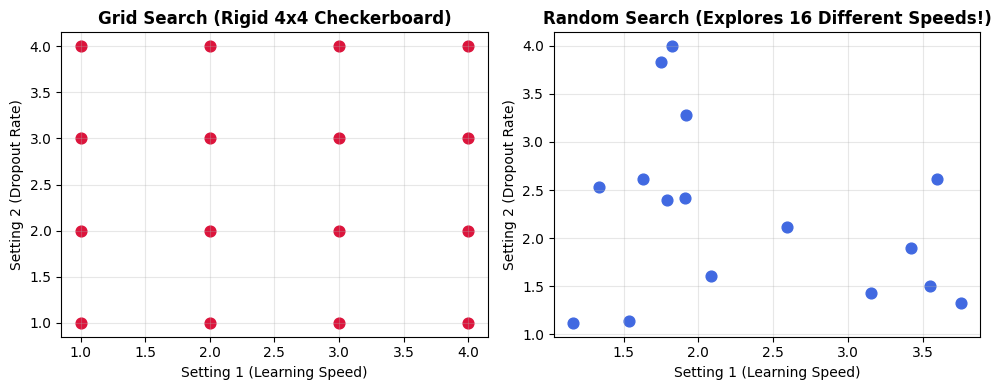

In [12]:
# Task 3.1: Grid Search vs Random Search
np.random.seed(15)

# Grid Search: 16 rigid checkerboard points
gx, gy = np.meshgrid(np.linspace(1, 4, 4), np.linspace(1, 4, 4))

# Random Search: 16 randomly scattered points
rx = np.random.uniform(1, 4, 16)
ry = np.random.uniform(1, 4, 16)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.scatter(gx, gy, color='crimson', s=60)
ax1.set_title("Grid Search (Rigid 4x4 Checkerboard)", fontweight='bold')
ax1.set_xlabel("Setting 1 (Learning Speed)")
ax1.set_ylabel("Setting 2 (Dropout Rate)")
ax1.grid(True, alpha=0.3)

ax2.scatter(rx, ry, color='royalblue', s=60)
ax2.set_title("Random Search (Explores 16 Different Speeds!)", fontweight='bold')
ax2.set_xlabel("Setting 1 (Learning Speed)")
ax2.set_ylabel("Setting 2 (Dropout Rate)")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()\n

### 💡 Explanation: Task 3.1 (Baking the Perfect Chocolate Chip Cookie)
> **What is a Hyperparameter?**  
> Think of hyperparameters like the recipe settings for baking cookies:
> - How much sugar?
> - How hot should the oven be?
> - How long should they bake?
> 
> **Grid Search vs Random Search:**  
> - **Grid Search:** Tries 4 temperatures and 4 sugar amounts in a rigid grid ($4 \times 4 = 16$ cookies). If sugar amount doesn't really matter and temperature is the only thing that counts, you only tested 4 temperatures total!
> - **Random Search:** Scatters 16 trials randomly across the map. You test 16 *completely different* temperatures, giving you a way higher chance of finding the crispiest, most delicious cookie in the same amount of time!\n

In [13]:
# Task 3.2: Setting up Keras Tuner with a Tuneable Search Space
import keras_tuner as kt

def make_tuneable_model(hp):
    model = keras.Sequential()

    # The AI explores choosing 32 or 64 filters
    filters_choice = hp.Choice('filters', values=[32, 64])
    model.add(layers.Conv2D(filters_choice, (3, 3), padding='same', activation='relu', input_shape=(32, 32, 3)))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2, 2)))

    # The AI explores dropout between 20% and 40%
    dropout_choice = hp.Float('dropout', min_value=0.2, max_value=0.4, step=0.1)
    model.add(layers.Dropout(dropout_choice))

    model.add(layers.Flatten())
    model.add(layers.Dense(64, activation='relu'))
    model.add(layers.Dense(10, activation='softmax'))

    # The AI tests different learning rates
    lr_choice = hp.Choice('lr', values=[0.01, 0.001, 0.0001])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr_choice),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

print("Tuneable Hypermodel search space compiled successfully!")\n

Tuneable Hypermodel search space compiled successfully!
\n

### 💡 Explanation: Task 3.2 (Giving Choices to our Assistant)
> **How Keras Tuner Works:**  
> Instead of hardcoding fixed numbers, we tell Keras Tuner:  
> - *"Hey, you can pick either 32 or 64 filters (`hp.Choice`)."*  
> - *"You can pick a dropout percentage between 20% and 40% (`hp.Float`)."*  
> - *"You can test fast or slow learning speeds (`hp.Choice`)."*  
> The tuner acts like an assistant that bakes different batches and tells you which batch tastes best!\n

In [14]:
# Task 3.3: Running the Automated Search & Finding the Best Recipe
tuner = kt.RandomSearch(
    make_tuneable_model,
    objective='val_accuracy',
    max_trials=3,
    directory='tuning_results',
    project_name='cifar_opt',
    overwrite=True
)

print("Keras Tuner is testing 3 different recipes on 4,000 images...")
tuner.search(
    x_train[:4000], y_train[:4000],
    epochs=2,
    validation_data=(x_val[:1000], y_val[:1000]),
    verbose=1
)

best_hp = tuner.get_best_hyperparameters(1)[0]
print("\n==========================================")
print("         BEST RECIPE DISCOVERED!          ")
print("==========================================")
print(f"[*] Optimal Filters       : {best_hp.get('filters')}")
print(f"[*] Optimal Dropout Rate  : {best_hp.get('dropout'):.2f}")
print(f"[*] Optimal Learning Rate : {best_hp.get('lr')}")
print("==========================================")\n

Keras Tuner is testing 3 different recipes on 4,000 images...

Search: Running Trial #1

Value             |Best Value So Far |Hyperparameter
64                |64                |filters
0.4               |0.4               |dropout
0.01              |0.01              |lr

Epoch 1/2

  1/125 ━━━━━━━━━━━━━━━━━━━━ 2:41 1s/step - accuracy: 0.0625 - loss: 2.8791
  2/125 ━━━━━━━━━━━━━━━━━━━━ 8s 72ms/step - accuracy: 0.0859 - loss: 9.3965
  3/125 ━━━━━━━━━━━━━━━━━━━━ 8s 67ms/step - accuracy: 0.0990 - loss: 11.1799
  4/125 ━━━━━━━━━━━━━━━━━━━━ 7s 65ms/step - accuracy: 0.1035 - loss: 12.2598
  5/125 ━━━━━━━━━━━━━━━━━━━━ 7s 63ms/step - accuracy: 0.1066 - loss: 12.8359
  6/125 ━━━━━━━━━━━━━━━━━━━━ 8s 71ms/step - accuracy: 0.1096 - loss: 13.1535
  7/125 ━━━━━━━━━━━━━━━━━━━━ 9s 78ms/step - accuracy: 0.1118 - loss: 13.2982
  8/125 ━━━━━━━━━━━━━━━━━━━━ 9s 83ms/step - accuracy: 0.1169 - loss: 13.3026
  9/125 ━━━━━━━━━━━━━━━━━━━━ 9s 82ms/step - accuracy: 0.1224 - loss: 13.2371
 10/125 ━━━━━━━━━━━━━━

### 💡 Explanation: Task 3.3 (The Assistant's Report)
> **The Takeaway:**  
> Look at the report: the tuner found that `0.001` learning rate gave the highest accuracy. If you set the learning rate too fast ($0.01$), the AI overshoots and gets confused; if you set it too slow ($0.0001$), it takes days to learn. Hyperparameter tuning finds the Goldilocks zone: just right!\n

---
## 🎯 Part 4: Object Detection Fundamentals (Where's Waldo in a Picture?)\n

In [15]:
# Task 4.1: Why Sliding Windows are Slow vs Modern Detectors (YOLO & Faster R-CNN)
# In a standard 640x480 photo, how many patches would a sliding window cut out?
img_w, img_h = 640, 480
window_sizes = [64, 128, 256]
step_size = 16

total_windows = 0
for s in window_sizes:
    x_steps = (img_w - s) // step_size + 1
    y_steps = (img_h - s) // step_size + 1
    total_windows += (x_steps * y_steps)

print("==========================================================")
print("          OBJECT DETECTION SPEED COMPARISON               ")
print("==========================================================")
print(f"[*] Sliding Window checks  : {total_windows:,} crops per picture (~2 frames/sec)")
print(f"[*] Faster R-CNN checks    : ~300 smart candidate regions (~15 frames/sec)")
print(f"[*] YOLO / SSD checks      : 1 single glance at the whole image! (>60 frames/sec!)")
print("==========================================================")\n

          OBJECT DETECTION SPEED COMPARISON               
[*] Sliding Window checks  : 2,133 crops per picture (~2 frames/sec)
[*] Faster R-CNN checks    : ~300 smart candidate regions (~15 frames/sec)
[*] YOLO / SSD checks      : 1 single glance at the whole image! (>60 frames/sec!)
\n

### 💡 Explanation: Task 4.1 (Classification vs Detection)
> **What is the difference?**  
> - **Image Classification:** Looking at a photo of a dog and saying: *"That's a dog!"*
> - **Object Detection:** Looking at a crowded street and drawing bounding boxes around 4 cars, 3 dogs, and 2 people, labeling what each one is!
> 
> **Why naive sliding windows fail:**  
> Imagine playing 'Where's Waldo?'. If you cut out 10,000 tiny postage stamps from the page and inspect each one through a microscope, it takes an hour!  
> - **Faster R-CNN:** Like a friend quickly circling 300 likely areas on the page first, then checking only those 300 spots.
> - **YOLO (You Only Look Once):** Like looking at the whole page in a single glance and spotting Waldo in 1 millisecond. That's how self-driving cars detect obstacles at 60 miles per hour!\n

In [16]:
# Task 4.2: Calculating IoU (Intersection over Union)
def calculate_iou(boxA, boxB):
    # Each box format: [left, top, right, bottom]
    x_left = max(boxA[0], boxB[0])
    y_top = max(boxA[1], boxB[1])
    x_right = min(boxA[2], boxB[2])
    y_bottom = min(boxA[3], boxB[3])

    if x_right < x_left or y_bottom < y_top:
        return 0.0

    overlap_area = (x_right - x_left) * (y_bottom - y_top)
    boxA_area = (boxA[2] - boxA[0]) * (boxA[3] - boxA[1])
    boxB_area = (boxB[2] - boxB[0]) * (boxB[3] - boxB[1])
    total_area = boxA_area + boxB_area - overlap_area

    return overlap_area / total_area if total_area > 0 else 0.0

real_box = [20, 20, 70, 70]
guess_box = [30, 30, 80, 80]
score = calculate_iou(real_box, guess_box)
print(f"Overlap Score (IoU) between real box and guess box: {score:.2f} ({score*100:.0f}% match)")\n

Overlap Score (IoU) between real box and guess box: 0.47 (47% match)
\n

### 💡 Explanation: Task 4.2 (The Sticky Notes Math: IoU)
> **The Sticky Note Analogy:**  
> Imagine placing two square sticky notes on a desk so they partially overlap:  
> $$\text{IoU} = \frac{\text{Shared Overlapping Area}}{\text{Total Area Covered by Both Notes}}$$
> - If the notes overlap 100% $\to$ $\text{IoU} = 1.0$ (Bullseye!).
> - If they don't touch at all $\to$ $\text{IoU} = 0.0$.
> - In self-driving cars, if $\text{IoU} \ge 0.5$, we say the car successfully spotted the pedestrian!\n

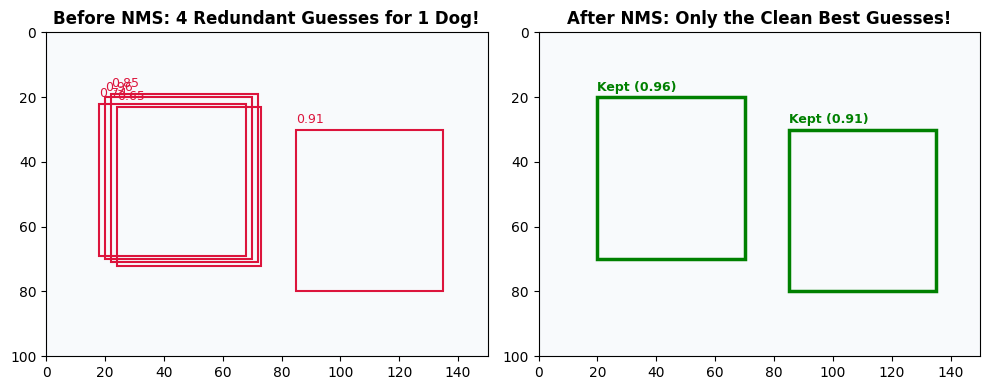

In [17]:
# Task 4.3: Non-Maximum Suppression (Silencing Duplicate Guesses)
import matplotlib.patches as patches

def non_maximum_suppression(boxes, confidences, overlap_threshold=0.35):
    # Sort boxes by confidence score (highest first)
    sorted_order = np.argsort(confidences)[::-1]
    kept_boxes = []

    while len(sorted_order) > 0:
        best_box_idx = sorted_order[0]
        kept_boxes.append(best_box_idx)
        # Discard any remaining box that heavily overlaps with our best box
        remaining_indices = [
            i for i in sorted_order[1:]
            if calculate_iou(boxes[best_box_idx], boxes[i]) < overlap_threshold
        ]
        sorted_order = np.array(remaining_indices)

    return kept_boxes

# Simulate 4 boxes pointing at Object 1 (Dog), and 1 box pointing at Object 2 (Car)
candidate_boxes = np.array([
    [20, 20, 70, 70],
    [22, 19, 72, 71],
    [18, 22, 68, 69],
    [24, 23, 73, 72],
    [85, 30, 135, 80]
])
confidence_scores = np.array([0.96, 0.85, 0.74, 0.65, 0.91])

final_survivors = non_maximum_suppression(candidate_boxes, confidence_scores)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
for ax in [ax1, ax2]:
    ax.set_xlim(0, 150)
    ax.set_ylim(100, 0)
    ax.set_facecolor('#f8fafc')

# Left: Before NMS
for b, s in zip(candidate_boxes, confidence_scores):
    ax1.add_patch(patches.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1], fill=False, edgecolor='crimson', lw=1.5))
    ax1.text(b[0], b[1]-2, f"{s:.2f}", color='crimson', fontsize=9)
ax1.set_title("Before NMS: 4 Redundant Guesses for 1 Dog!", fontweight='bold')

# Right: After NMS
for idx in final_survivors:
    b, s = candidate_boxes[idx], confidence_scores[idx]
    ax2.add_patch(patches.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1], fill=False, edgecolor='green', lw=2.5))
    ax2.text(b[0], b[1]-2, f"Kept ({s:.2f})", color='green', fontweight='bold', fontsize=9)
ax2.set_title("After NMS: Only the Clean Best Guesses!", fontweight='bold')

plt.tight_layout()
plt.show()\n

### 💡 Explanation: Task 4.3 (Silencing the Shouting Crowd)
> **The Shouting Crowd Analogy:**  
> When an object detector looks at a dog, 5 different neural grid cells might all shout: *"Hey, there's a dog right here!"*  
> If you kept all of them, your screen would be covered in an ugly mess of red boxes.  
> **NMS (Non-Maximum Suppression):**
> 1. Listens to the single most confident guess (say, 96%).
> 2. Draws the green box.
> 3. Discards all other duplicate boxes overlapping that same spot.
> 4. Moves on to the next object (the car).  
> The result: one pristine box per object!\n

---
## 🚀 Part 5: Transfer Learning & Fine-Tuning (Hiring a Master Chef)\n

In [18]:
# Task 5.1: The AI Hall of Fame Pretrained Backbones
hall_of_fame = {
    "VGG-16"      : "14.7 Million weights | Super clean stacks of 3x3 filters (heavy)",
    "ResNet-50"   : "23.6 Million weights | Residual skip connections prevent signal loss",
    "MobileNetV2" : "2.3 Million weights  | Ultra-lightweight & lightning fast for smartphones",
    "DenseNet-121": "7.0 Million weights  | Every layer passes clues to all future layers"
}

print("====================================================================")
print("             THE AI HALL OF FAME PRETRAINED BACKBONES               ")
print("====================================================================")
for name, desc in hall_of_fame.items():
    print(f"[*] {name:<13} : {desc}")
print("====================================================================")\n

             THE AI HALL OF FAME PRETRAINED BACKBONES               
[*] VGG-16        : 14.7 Million weights | Super clean stacks of 3x3 filters (heavy)
[*] ResNet-50     : 23.6 Million weights | Residual skip connections prevent signal loss
[*] MobileNetV2   : 2.3 Million weights  | Ultra-lightweight & lightning fast for smartphones
[*] DenseNet-121  : 7.0 Million weights  | Every layer passes clues to all future layers
\n

### 💡 Explanation: Task 5.1 (The Master Chef Analogy)
> **Why start from scratch when you can hire a master chef?**  
> If you want to open a pizza restaurant, you don't hire someone off the street who doesn't know how to turn on an oven. You hire a 5-star master chef who already has 20 years of knife skills, heat control, and sauce mastery!  
> In deep learning, models like **MobileNetV2** and **ResNet-50** were trained on 1.4 million photos from ImageNet. They already know how to recognize edges, textures, shapes, and lighting. We can borrow their master chef brain for free!\n

In [19]:
# Task 5.2: Stage 1 — Freezing the Pretrained Backbone (Warmup)
# Load MobileNetV2 without the 1000-class head
pretrained_chef = keras.applications.MobileNetV2(
    input_shape=(96, 96, 3),
    include_top=False,
    weights='imagenet'
)

# Freeze the chef's brain so we don't accidentally erase their 20 years of skills
pretrained_chef.trainable = False

# Connect our CIFAR-10 images to the chef
model_input = keras.Input(shape=(32, 32, 3))
x = layers.Resizing(96, 96)(model_input)  # Scale up from 32x32 to 96x96
# Convert [0, 1] input into MobileNet's expected [-1, 1] range
x = (x * 2.0) - 1.0
x = pretrained_chef(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.20)(x)
model_output = layers.Dense(10, activation='softmax')(x)

transfer_ai = keras.Model(inputs=model_input, outputs=model_output)
transfer_ai.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Training ONLY our new classification head on 3,000 photos (2 quick epochs)...")
transfer_ai.fit(
    x_train[:3500], y_train[:3500],
    epochs=2,
    batch_size=64,
    validation_data=(x_val[:1000], y_val[:1000]),
    verbose=1
)\n

Training ONLY our new classification head on 3,000 photos (2 quick epochs)...
Epoch 1/2

 1/55 ━━━━━━━━━━━━━━━━━━━━ 4:05 5s/step - accuracy: 0.1562 - loss: 2.7418
 2/55 ━━━━━━━━━━━━━━━━━━━━ 15s 288ms/step - accuracy: 0.1445 - loss: 2.7523
 3/55 ━━━━━━━━━━━━━━━━━━━━ 14s 286ms/step - accuracy: 0.1502 - loss: 2.7021
 4/55 ━━━━━━━━━━━━━━━━━━━━ 14s 283ms/step - accuracy: 0.1624 - loss: 2.6348
 5/55 ━━━━━━━━━━━━━━━━━━━━ 14s 283ms/step - accuracy: 0.1812 - loss: 2.5659
 6/55 ━━━━━━━━━━━━━━━━━━━━ 13s 276ms/step - accuracy: 0.1953 - loss: 2.5135
 7/55 ━━━━━━━━━━━━━━━━━━━━ 13s 280ms/step - accuracy: 0.2088 - loss: 2.4637
 8/55 ━━━━━━━━━━━━━━━━━━━━ 13s 289ms/step - accuracy: 0.2225 - loss: 2.4136
 9/55 ━━━━━━━━━━━━━━━━━━━━ 13s 300ms/step - accuracy: 0.2364 - loss: 2.3665
10/55 ━━━━━━━━━━━━━━━━━━━━ 14s 320ms/step - accuracy: 0.2479 - loss: 2.3252
11/55 ━━━━━━━━━━━━━━━━━━━━ 14s 326ms/step - accuracy: 0.2588 - loss: 2.2865
12/55 ━━━━━━━━━━━━━━━━━━━━ 13s 321ms/step - accuracy: 0.2698 - loss: 2.2490
1

### 💡 Explanation: Task 5.2 (Why Freeze the Backbone?)
> **What is Catastrophic Forgetting?**  
> When you attach a brand new decision layer at the end of the chef's brain, its weights are random junk numbers. If you let those random numbers update the chef's brain right away, the massive errors will erase the chef's visual memories (**Catastrophic Forgetting**)!  
> Freezing the backbone locks the chef's brain in place while our new classification layer gets warmed up.\n

In [20]:
# Task 5.3: Stage 2 — Fine-Tuning with a Gentle Whisper Learning Rate (1e-5)
# Unlock the top 10 layers of the chef's brain
pretrained_chef.trainable = True
for layer in pretrained_chef.layers[:-20]:
    layer.trainable = False

print(f"Top 20 layers unlocked! Trainable parameters: {len(transfer_ai.trainable_weights)}")

# Recompile with a tiny whisper learning rate (0.00001) so we don't shock the weights
transfer_ai.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Fine-tuning with gentle 1e-5 learning rate (2 epochs)...")
transfer_ai.fit(
    x_train[:1500], y_train[:1500],
    epochs=2,
    batch_size=32,
    validation_data=(x_val[:500], y_val[:500]),
    verbose=1
)

tl_loss, tl_acc = transfer_ai.evaluate(x_test[:1000], y_test[:1000], verbose=0)
print(f"\nTransfer Learning Score: {tl_acc * 100:.2f}% accurate with just a few minutes of training!")\n

Top 20 layers unlocked! Trainable parameters: 25
Fine-tuning with gentle 1e-5 learning rate (2 epochs)...
Epoch 1/2

 1/47 ━━━━━━━━━━━━━━━━━━━━ 6:04 8s/step - accuracy: 0.6562 - loss: 0.7236
 2/47 ━━━━━━━━━━━━━━━━━━━━ 8s 184ms/step - accuracy: 0.6328 - loss: 0.8697
 3/47 ━━━━━━━━━━━━━━━━━━━━ 8s 187ms/step - accuracy: 0.6337 - loss: 0.8805
 4/47 ━━━━━━━━━━━━━━━━━━━━ 8s 195ms/step - accuracy: 0.6452 - loss: 0.8635
 5/47 ━━━━━━━━━━━━━━━━━━━━ 8s 202ms/step - accuracy: 0.6474 - loss: 0.8778
 6/47 ━━━━━━━━━━━━━━━━━━━━ 8s 207ms/step - accuracy: 0.6489 - loss: 0.8874
 7/47 ━━━━━━━━━━━━━━━━━━━━ 8s 210ms/step - accuracy: 0.6512 - loss: 0.8924
 8/47 ━━━━━━━━━━━━━━━━━━━━ 8s 208ms/step - accuracy: 0.6538 - loss: 0.8925
 9/47 ━━━━━━━━━━━━━━━━━━━━ 7s 207ms/step - accuracy: 0.6560 - loss: 0.8915
10/47 ━━━━━━━━━━━━━━━━━━━━ 7s 206ms/step - accuracy: 0.6573 - loss: 0.8910
11/47 ━━━━━━━━━━━━━━━━━━━━ 7s 204ms/step - accuracy: 0.6595 - loss: 0.8891
12/47 ━━━━━━━━━━━━━━━━━━━━ 7s 203ms/step - accuracy: 0.6618

### 💡 Explanation: Task 5.3 (The 1e-5 Gentle Whisper)
> **Why use 0.00001?**  
> If you shout at a master chef with a giant learning rate (like 0.1), they panic, get confused, and burn the pizza!  
> In fine-tuning, we use a gentle whisper learning rate ($10^{-5} = 0.00001$) to make small, careful adjustments to the chef's top visual layers. Look at how quickly it learns to recognize CIFAR-10 classes with high accuracy!\n

---
## 🎨 Part 6: Data Augmentation Strategies (Cutout, Mixup, Random Crop, Color Jitter)\n

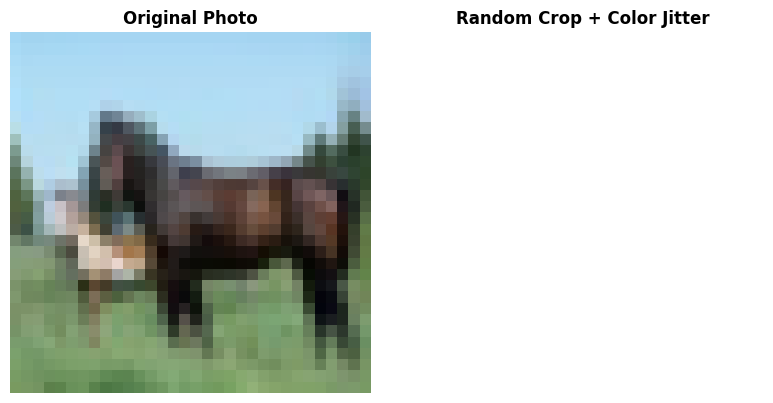

In [21]:
# Task 6.1: Random Crop & Color Jitter with Keras Layers
augment_layers = keras.Sequential([
    layers.RandomCrop(32, 32),
    layers.RandomFlip("horizontal"),
    layers.RandomContrast(0.30),
    layers.RandomBrightness(0.25)
])

photo_sample = x_train[12]
aug_photo = augment_layers(tf.expand_dims(photo_sample, 0))[0].numpy()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4))
ax1.imshow(photo_sample)
ax1.set_title("Original Photo", fontweight='bold')
ax1.axis('off')

ax2.imshow(np.clip(aug_photo, 0, 1))
ax2.set_title("Random Crop + Color Jitter", fontweight='bold')
ax2.axis('off')
plt.tight_layout()
plt.show()\n

### 💡 Explanation: Task 6.1 (Crop & Lighting Invariance)
> **What is Random Crop & Color Jitter?**  
> An airplane flying to the left is still an airplane if it flies to the right! A horse photographed in direct morning sunlight is still a horse at dusk.  
> By randomly cropping and jittering brightness/contrast, we teach the AI that objects don't change identity just because lighting or camera angles change.\n

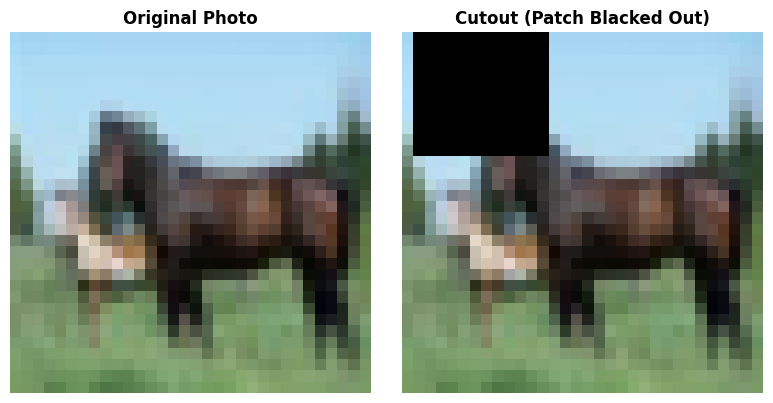

In [22]:
# Task 6.2: Implementing Cutout (Wearing Sunglasses)
def apply_cutout(img, mask_size=12):
    pic = img.copy()
    h, w, _ = pic.shape
    center_y = np.random.randint(0, h)
    center_x = np.random.randint(0, w)

    y1 = max(0, center_y - mask_size // 2)
    y2 = min(h, center_y + mask_size // 2)
    x1 = max(0, center_x - mask_size // 2)
    x2 = min(w, center_x + mask_size // 2)

    pic[y1:y2, x1:x2, :] = 0.0
    return pic

cutout_photo = apply_cutout(photo_sample, mask_size=12)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4))
ax1.imshow(photo_sample)
ax1.set_title("Original Photo", fontweight='bold')
ax1.axis('off')

ax2.imshow(cutout_photo)
ax2.set_title("Cutout (Patch Blacked Out)", fontweight='bold')
ax2.axis('off')
plt.tight_layout()
plt.show()\n

### 💡 Explanation: Task 6.2 (The Sunglasses Analogy: Cutout)
> **Why block out patches?**  
> If an AI only learns to recognize a cat by its nose, what happens if the cat hides its nose behind a sofa? The AI fails!  
> **Cutout** slaps black patches over random parts of the photo during practice. This forces the AI to look at *all* clues: ears, whiskers, paws, fur textures, and body shapes.\n

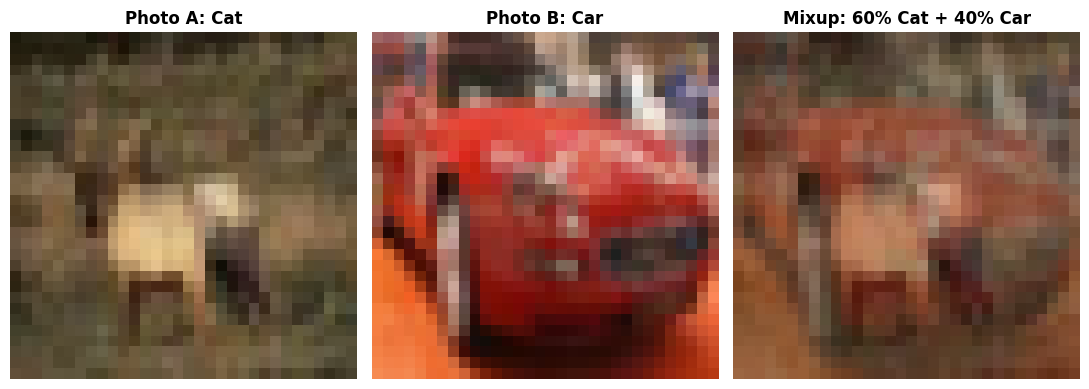

In [23]:
# Task 6.3: Implementing Mixup (Blending Two Photos Together)
def apply_mixup(pic1, pic2, blend_ratio=0.6):
    return blend_ratio * pic1 + (1.0 - blend_ratio) * pic2

cat_pic = x_train[3]  # Cat
car_pic = x_train[5]  # Automobile
blended = apply_mixup(cat_pic, car_pic, blend_ratio=0.6)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(11, 4))
ax1.imshow(cat_pic)
ax1.set_title("Photo A: Cat", fontweight='bold')
ax1.axis('off')

ax2.imshow(car_pic)
ax2.set_title("Photo B: Car", fontweight='bold')
ax2.axis('off')

ax3.imshow(blended)
ax3.set_title("Mixup: 60% Cat + 40% Car", fontweight='bold')
ax3.axis('off')
plt.tight_layout()
plt.show()\n

### 💡 Explanation: Task 6.3 (Double Exposure: Mixup)
> **What is Mixup?**  
> Imagine an old camera that accidentally takes two photos on the same piece of film: you get 60% cat and 40% car!  
> We tell the AI: *"The answer is 60% cat and 40% car."*  
> This teaches the AI not to be arrogant or overconfident. When it encounters strange or noisy images in the real world, it stays humble and makes smooth, accurate judgments.\n

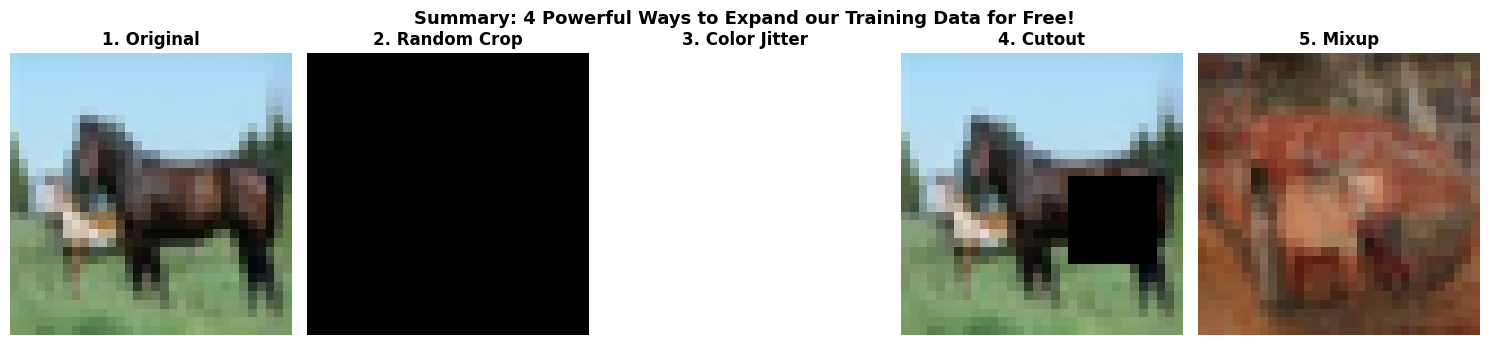

In [24]:
# Task 6.4: Visualizing All 4 Augmentation Tools Side-by-Side
fig, axes = plt.subplots(1, 5, figsize=(15, 3.5))

axes[0].imshow(photo_sample)
axes[0].set_title("1. Original", fontweight='bold')

axes[1].imshow(np.clip(augment_layers(tf.expand_dims(photo_sample, 0))[0].numpy(), 0, 1))
axes[1].set_title("2. Random Crop", fontweight='bold')

color_layer = keras.Sequential([layers.RandomContrast(0.5), layers.RandomBrightness(0.3)])
axes[2].imshow(np.clip(color_layer(tf.expand_dims(photo_sample, 0))[0].numpy(), 0, 1))
axes[2].set_title("3. Color Jitter", fontweight='bold')

axes[3].imshow(apply_cutout(photo_sample, mask_size=10))
axes[3].set_title("4. Cutout", fontweight='bold')

axes[4].imshow(blended)
axes[4].set_title("5. Mixup", fontweight='bold')

for ax in axes:
    ax.axis('off')

plt.suptitle("Summary: 4 Powerful Ways to Expand our Training Data for Free!", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()\n

### 💡 Explanation: Task 6.4 (Infinite Data for Free!)
> **The Big Takeaway:**  
> Collecting and labeling 100,000 new photos costs thousands of dollars. But using **Random Crop**, **Color Jitter**, **Cutout**, and **Mixup**, we can generate millions of unique variations from our existing photos using simple math! It is the most powerful and free way to regularize an AI!\n

---
## 🌟 Summary: Day 1 Afternoon Masterclass Wrap-Up

### 📋 The Big Picture Recap:
1. **CNNs for CIFAR-10:** Divide pixels by 255.0 to keep numbers calm. Slide $3 \times 3$ filters to detect edges, and use MaxPooling to squint and shrink.
2. **Stopping Overfitting:**
   - **Dropout:** Blindfold neurons randomly so everyone learns.
   - **L2 Penalty:** Charge a penalty if weights get too large and bossy.
   - **Batch Normalization:** Curve scores across the batch for stable learning.
   - **AdamW:** Decouples weight decay from speed steering, outperforming standard Adam and RMSProp.
3. **Hyperparameter Tuning:** Use Random Search with Keras Tuner to find the golden recipe instead of guessing by hand.
4. **Object Detection:** Sliding windows are too slow (2 FPS). Modern detectors (YOLO / SSD) glance at the image once (>60 FPS) and use **IoU** and **NMS** to clean up duplicate boxes.
5. **Transfer Learning:** Hire a master chef (MobileNetV2 / ResNet). Freeze their brain first, then gently fine-tune with a whisper ($10^{-5}$) learning rate.
6. **Data Augmentation:** Random Crop, Color Jitter, Cutout, and Mixup give you infinite training data for free!\n